## Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

RANDOM_STATE = 42
TARGET = "Attack_type"
PORT_COLUMNS = ["id.orig_p", "id.resp_p"]


## Đọc dữ liệu

In [2]:
# Đặt train.csv và validation.csv cùng thư mục với notebook.
TRAIN_PATH = "data\\train.csv"
VALIDATION_PATH = "data\\validation.csv"

train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)

print("Train shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Train columns:", len(train_df.columns))
print("Validation columns:", len(validation_df.columns))

assert TARGET in train_df.columns, f"Không tìm thấy {TARGET} trong train"
assert TARGET in validation_df.columns, f"Không tìm thấy {TARGET} trong validation"
assert set(train_df.columns) == set(validation_df.columns), "Train và validation không cùng tập cột"
missing_ports = [c for c in PORT_COLUMNS if c not in train_df.columns]
assert not missing_ports, f"Thiếu cột cổng: {missing_ports}"


Train shape: (82536, 83)
Validation shape: (17686, 83)
Train columns: 83
Validation columns: 83


## kiểm tra dữ liệu và giá trị của 2 cột cổng

In [3]:
display(train_df[PORT_COLUMNS].dtypes.to_frame("dtype"))
display(train_df[PORT_COLUMNS].describe(percentiles=[.25, .5, .75]).T)

for col in PORT_COLUMNS:
    print(f"\\n{col}")
    print("Số giá trị thiếu:", train_df[col].isna().sum())
    print("Số giá trị cổng khác nhau:", train_df[col].nunique(dropna=True))
    print("Số giá trị xuất hiện:", train_df[col].notna().sum())


,dtype
id.orig_p,int64
id.resp_p,int64


,count,mean,std,min,25%,50%,75%,max
id.orig_p,82536.0,35029.395815,18940.696081,0.0,18534.75,37639.0,51036.0,65535.0
id.resp_p,82536.0,1054.523820,5379.550258,0.0,21.00,21.0,21.0,65389.0


\nid.orig_p
Số giá trị thiếu: 0
Số giá trị cổng khác nhau: 53350
Số giá trị xuất hiện: 82536
\nid.resp_p
Số giá trị thiếu: 0
Số giá trị cổng khác nhau: 1711
Số giá trị xuất hiện: 82536


## Phân tích phụ thuộc giữa cổng và Attack_type (chỉ trên train)

## Phân phối nhãn theo các cổng phổ biến

In [4]:
for col in PORT_COLUMNS:
    print(f"Top 20 giá trị của {col}:")
    top_ports = train_df[col].value_counts(dropna=False).head(20).index
    subset = train_df[train_df[col].isin(top_ports)]
    port_target_pct = pd.crosstab(
        subset[col],
        subset[TARGET],
        normalize="index"
    ) * 100
    display(port_target_pct.round(2))


Top 20 giá trị của id.orig_p:


Attack_type,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,Metasploit_Brute_Force_SSH,NMAP_OS_DETECTION,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
id.orig_p,,,,,,,,,
68,38.46,7.69,0.00,0.00,0.00,0.00,0.0,30.77,23.08
143,0.00,0.00,18.18,0.00,0.00,0.00,0.0,81.82,0.00
5353,55.26,2.63,1.32,2.63,0.00,10.53,0.0,27.63,0.00
36242,0.00,0.00,0.00,0.00,0.00,0.00,100.0,0.00,0.00
46600,0.14,0.00,0.14,0.00,99.72,0.00,0.0,0.00,0.00
50078,0.00,0.00,0.17,0.00,0.00,99.83,0.0,0.00,0.00
50079,0.00,0.00,0.63,0.00,0.00,99.37,0.0,0.00,0.00
50080,5.56,0.00,0.00,0.00,0.00,94.44,0.0,0.00,0.00
50081,0.00,0.00,8.33,0.00,0.00,91.67,0.0,0.00,0.00


Top 20 giá trị của id.resp_p:


Attack_type,ARP_poisioning,DDOS_Slowloris,DOS_SYN_Hping,MQTT_Publish,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN,NMAP_OS_DETECTION,NMAP_TCP_scan,NMAP_UDP_SCAN,NMAP_XMAS_TREE_SCAN,Thing_Speak,Wipro_bulb
id.resp_p,,,,,,,,,,,,
21,0.00,0.00,99.99,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
22,0.00,0.00,0.00,0.00,43.18,38.64,2.27,2.27,6.82,6.82,0.00,0.00
53,45.21,0.00,0.00,0.00,0.06,0.06,0.04,0.02,0.16,0.06,53.69,0.69
67,35.71,7.14,0.00,0.00,0.00,0.00,0.00,0.00,7.14,0.00,28.57,21.43
80,4.74,15.81,0.00,0.13,0.04,0.00,0.09,0.04,4.14,0.13,74.88,0.00
123,7.32,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.44,0.00,90.24,0.00
137,99.26,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.37,0.00,0.37,0.00
443,59.98,0.00,0.00,0.00,0.00,0.00,0.09,0.05,0.19,0.09,36.59,3.01
631,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,95.00,5.00,0.00,0.00


## Tần suất các cổng phổ biến

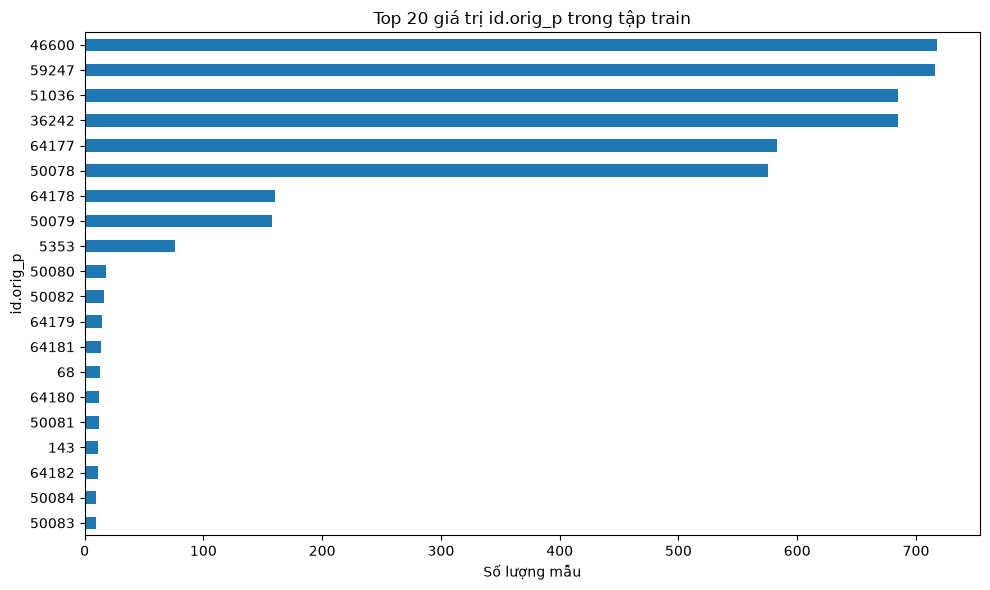

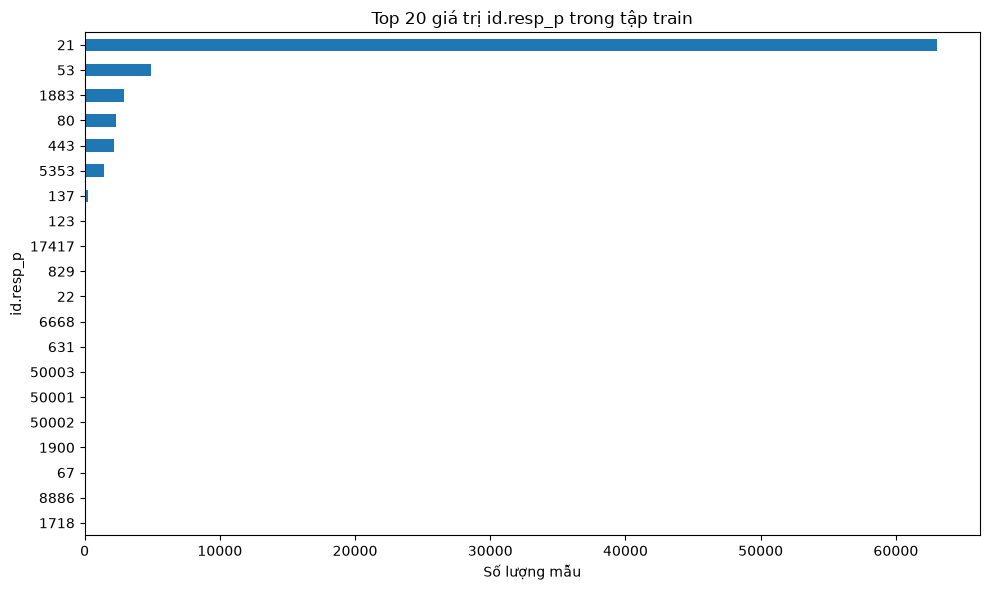

In [5]:
for col in PORT_COLUMNS:
    counts = train_df[col].value_counts().head(20).sort_values()
    plt.figure(figsize=(10, 6))
    counts.plot(kind="barh")
    plt.title(f"Top 20 giá trị {col} trong tập train")
    plt.xlabel("Số lượng mẫu")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


## Mức độ liên hệ bằng Mutual Information

In [6]:
# Mã hóa nhãn thành số nguyên để tính mutual information.
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(train_df[TARGET].astype(str))

mi_rows = []
for col in PORT_COLUMNS:
    # Điền giá trị thiếu bằng một nhãn riêng rồi mã hóa các giá trị cổng.
    port_values = train_df[col].astype("string").fillna("__MISSING__")
    port_codes, uniques = pd.factorize(port_values, sort=True)

    mi = mutual_info_classif(
        port_codes.reshape(-1, 1),
        y_encoded,
        discrete_features=True,
        random_state=RANDOM_STATE
    )[0]

    mi_rows.append({
        "feature": col,
        "unique_port_values": len(uniques),
        "mutual_information": mi
    })

mi_report = pd.DataFrame(mi_rows).sort_values(
    "mutual_information", ascending=False
)
display(mi_report)


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:49: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_label = type_of_target(labels_true)


,feature,unique_port_values,mutual_information
1,id.resp_p,1711,0.841033
0,id.orig_p,53350,0.763444


### Nhận xét kết quả
Diễn giải kết quả sau khi chạy:
- Nếu một cổng tập trung vào một hoặc một vài lớp Attack_type, cổng đó có khả năng mang thông tin dự đoán về nhãn.
- Mutual Information càng lớn thì mức độ phụ thuộc thống kê giữa cột cổng và nhãn càng đáng chú ý.
- Mối liên hệ này có thể phản ánh đặc điểm dịch vụ/mẫu lưu lượng của bộ dữ liệu; không đủ để kết luận cổng là nguyên nhân gây ra loại tấn công.
- Dù có thể mang thông tin dự đoán, E09 chủ động loại hai cột cổng để hạn chế mô hình phụ thuộc vào định danh cổng và kiểm tra khả năng học từ các đặc trưng lưu lượng còn lại

## Loại bỏ id.orig_p và id.resp_p

In [7]:
# Danh sách cột bị loại được cố định theo yêu cầu của E09.
drop_columns = PORT_COLUMNS.copy()

X_train = train_df.drop(columns=[TARGET]).copy()
y_train = train_df[TARGET].copy()

X_validation = validation_df.drop(columns=[TARGET]).copy()
y_validation = validation_df[TARGET].copy()

X_train_processed = X_train.drop(columns=drop_columns)
X_validation_processed = X_validation.drop(columns=drop_columns)

print("Train trước khi loại:", X_train.shape)
print("Train sau khi loại:", X_train_processed.shape)
print("Validation trước khi loại:", X_validation.shape)
print("Validation sau khi loại:", X_validation_processed.shape)

assert not set(drop_columns).intersection(X_train_processed.columns)
assert not set(drop_columns).intersection(X_validation_processed.columns)
assert X_train_processed.columns.tolist() == X_validation_processed.columns.tolist()


Train trước khi loại: (82536, 82)
Train sau khi loại: (82536, 80)
Validation trước khi loại: (17686, 82)
Validation sau khi loại: (17686, 80)


## Kiểm tra các cột còn lại

In [8]:
print("Các cột đã loại:", drop_columns)
print("Số đặc trưng còn lại:", X_train_processed.shape[1])
print("Còn id.orig_p?", "id.orig_p" in X_train_processed.columns)
print("Còn id.resp_p?", "id.resp_p" in X_train_processed.columns)

feature_summary = pd.DataFrame({
    "feature": X_train_processed.columns,
    "dtype": X_train_processed.dtypes.astype(str).values,
    "missing_train": X_train_processed.isna().sum().values,
    "missing_validation": X_validation_processed.isna().sum().values
})
display(feature_summary)


Các cột đã loại: ['id.orig_p', 'id.resp_p']
Số đặc trưng còn lại: 80
Còn id.orig_p? False
Còn id.resp_p? False


,feature,dtype,missing_train,missing_validation
0,proto,object,0,0
1,service,object,0,0
2,flow_duration,float64,0,0
3,fwd_pkts_tot,int64,0,0
4,bwd_pkts_tot,int64,0,0
...,...,...,...,...
75,idle.avg,float64,0,0
76,idle.std,float64,0,0
77,fwd_init_window_size,int64,0,0
78,bwd_init_window_size,int64,0,0


In [11]:
from pathlib import Path
import json

# Lưu dữ liệu sau bước xử lý của E09
OUTPUT_DIR = Path("../../project/preprocessing/data/E09_RF_Processing")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

processed_train = X_train_processed.copy()
processed_train[TARGET] = y_train.to_numpy()

processed_validation = X_validation_processed.copy()
processed_validation[TARGET] = y_validation.to_numpy()

# Lưu dữ liệu CSV trực tiếp vào OUTPUT_DIR
processed_train.to_csv(
    OUTPUT_DIR / "train.csv.gz",
    index=False,
    compression="gzip"
)

processed_validation.to_csv(
    OUTPUT_DIR / "validation.csv.gz",
    index=False,
    compression="gzip"
)

# Lưu cấu hình tiền xử lý JSON cùng thư mục
with (OUTPUT_DIR / "E09_processing_config.json").open("w", encoding="utf-8") as f:
    json.dump({
        "target": TARGET,
        "removed_columns": drop_columns,
        "feature_columns": X_train_processed.columns.tolist(),
    }, f, ensure_ascii=False, indent=2)

print("Đã lưu:", OUTPUT_DIR / "train.csv.gz")
print("Đã lưu:", OUTPUT_DIR / "validation.csv.gz")
print("Đã lưu:", OUTPUT_DIR / "E09_processing_config.json")


Đã lưu: ..\..\project\preprocessing\data\E09_RF_Processing\train.csv.gz
Đã lưu: ..\..\project\preprocessing\data\E09_RF_Processing\validation.csv.gz
Đã lưu: ..\..\project\preprocessing\data\E09_RF_Processing\E09_processing_config.json
